In [3]:
import pandas as pd

df = pd.read_csv("European_Bank_EDA.csv")

print(df.shape)
df.head()

(10100, 14)


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619.0,France,Female,42.0,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608.0,Spain,Female,41.0,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502.0,France,Female,42.0,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699.0,France,Female,39.0,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850.0,Spain,Female,43.0,2,125510.82,1,1,1,79084.10,0


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Year                 0
CustomerId           0
Surname              0
CreditScore        100
Geography          101
Gender             102
Age                101
Tenure               0
Balance            102
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary    101
Exited               0
dtype: int64

Total missing values: 607
Duplicate rows: 100


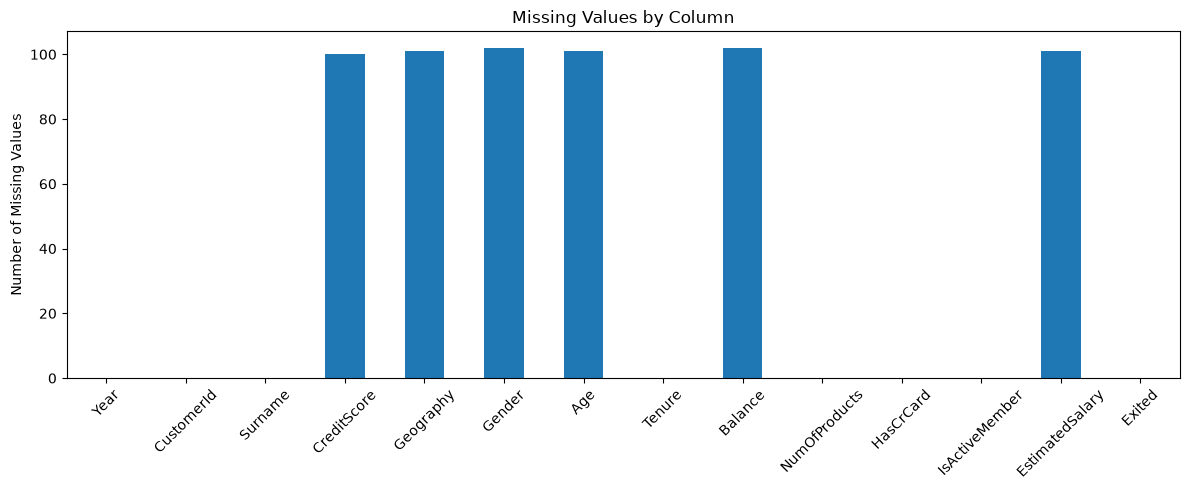

In [5]:
import matplotlib.pyplot as plt

df.isnull().sum().plot(kind="bar", figsize=(12, 5))
plt.title("Missing Values by Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Identify numerical and categorical columns
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(include=["str", "category"]).columns

# Fill numerical missing values with median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Verify
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [11]:
print("Dataset shape:", df.shape)

print("\nStatistical summary:")
display(df.describe())

print("\nCustomer distribution:")
print(df["Geography"].value_counts())

Dataset shape: (10000, 14)

Statistical summary:


,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.00000,10000.000000
mean,2025.0,1.569094e+07,650.5730,38.897600,5.012800,76643.496224,1.530200,0.70550,0.515100,100104.76143,0.203700
std,0.0,7.193619e+04,96.1736,10.447566,2.892174,62118.837400,0.581654,0.45584,0.499797,57176.13737,0.402769
min,2025.0,1.556570e+07,350.0000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.58000,0.000000
25%,2025.0,1.562853e+07,584.0000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51637.42750,0.000000
50%,2025.0,1.569074e+07,652.0000,37.000000,5.000000,97245.995000,1.000000,1.00000,1.000000,100314.07000,0.000000
75%,2025.0,1.575323e+07,717.0000,44.000000,7.000000,127334.445000,2.000000,1.00000,1.000000,148754.89000,0.000000
max,2025.0,1.581569e+07,850.0000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.48000,1.000000



Customer distribution:
Geography
France     5075
Germany    2472
Spain      2453
Name: count, dtype: int64


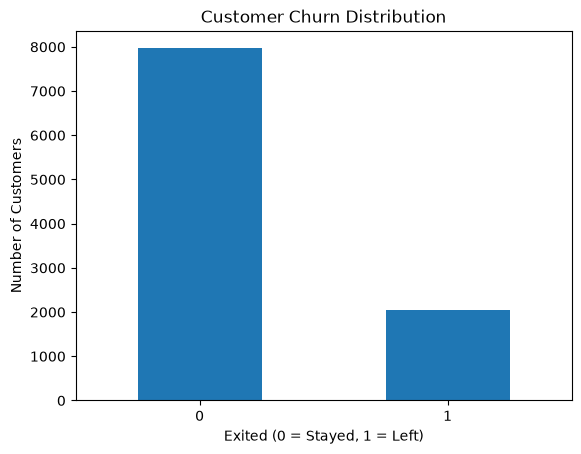

Churn percentage: 20.37 %


In [12]:
import matplotlib.pyplot as plt

churn_counts = df["Exited"].value_counts().sort_index()

churn_counts.plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

print("Churn percentage:", round(df["Exited"].mean() * 100, 2), "%")

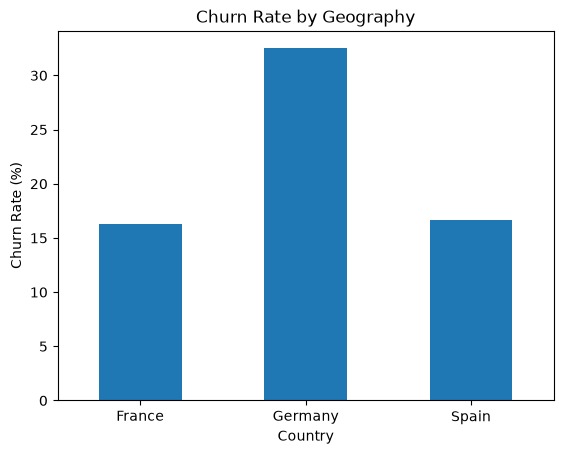

Geography
France     16.26
Germany    32.48
Spain      16.67
Name: Exited, dtype: float64

In [13]:
churn_by_country = df.groupby("Geography")["Exited"].mean() * 100

churn_by_country.plot(kind="bar")
plt.title("Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

display(churn_by_country.round(2))

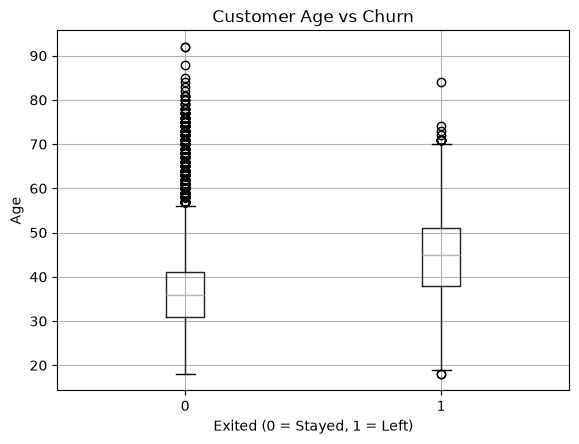

In [14]:
df.boxplot(column="Age", by="Exited")
plt.title("Customer Age vs Churn")
plt.suptitle("")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Age")
plt.show()

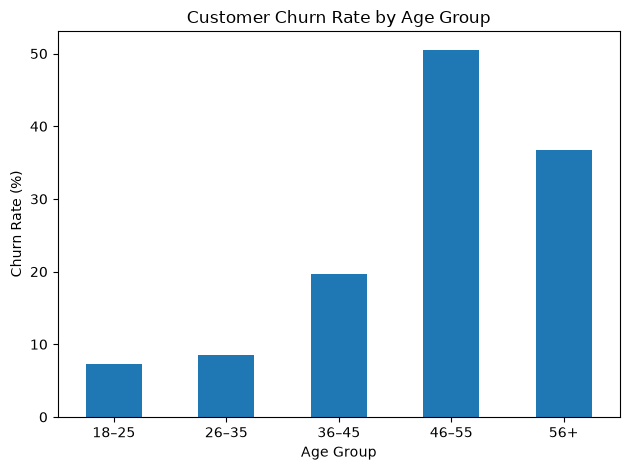

AgeGroup
18–25     7.25
26–35     8.51
36–45    19.67
46–55    50.54
56+      36.79
Name: Exited, dtype: float64


In [15]:
import pandas as pd
import matplotlib.pyplot as plt

bins = [0, 25, 35, 45, 55, 100]
labels = ["18–25", "26–35", "36–45", "46–55", "56+"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

age_churn = df.groupby(
    "AgeGroup", observed=False
)["Exited"].mean() * 100

age_churn.plot(kind="bar")
plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(age_churn.round(2))

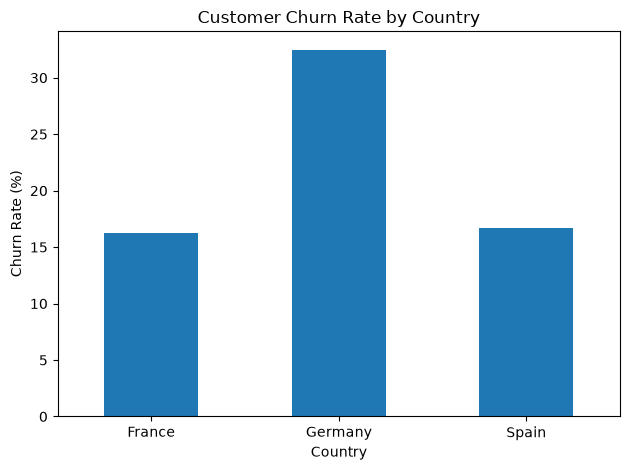

Geography
France     16.26
Germany    32.48
Spain      16.67
Name: Exited, dtype: float64


In [16]:
import matplotlib.pyplot as plt

country_churn = df.groupby("Geography")["Exited"].mean() * 100

country_churn.plot(kind="bar")
plt.title("Customer Churn Rate by Country")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(country_churn.round(2))

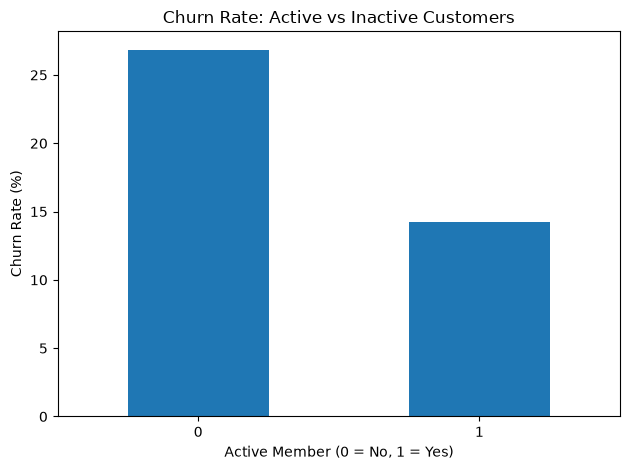

IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64


In [17]:
activity_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

activity_churn.plot(kind="bar")
plt.title("Churn Rate: Active vs Inactive Customers")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(activity_churn.round(2))